# Module 1 (CO1): Exploratory Data Analysis (EDA)
**Project**: Anti-Money Laundering Detection (IBM Benchmark)  
**Focus**: Distribution analysis, transaction typology breakdown, and feature correlations.

In [1]:
# 1. Load Dataset & Initial Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r'../data/ibm_aml_transactions.csv')
print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
df.head()


Dataset Shape: (100000, 11)

First 5 Records:


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/02 19:08,701,800C62FB0,1853,801CF2040,1688.21,US Dollar,1688.21,US Dollar,Credit Card,0
1,2022/09/07 14:56,12,80C7762B0,32564,80CCDA150,36107.76,Mexican Peso,36107.76,Mexican Peso,Credit Card,0
2,2022/09/04 05:38,24840,8025DD1B0,23691,80312DF90,2963.72,Euro,2963.72,Euro,Cheque,0
3,2022/09/07 01:29,5627,802F88510,18067,803106450,8500.01,Yuan,8500.01,Yuan,Cheque,0
4,2022/09/01 23:02,133452,80C99A850,133686,80C65D1C0,5157.01,Mexican Peso,5157.01,Mexican Peso,Cheque,0


## 2. Dynamic EDA Dashboard: Distributions & Typologies

C:\Users\Vishnu\AppData\Local\Temp\ipykernel_39520\1225504291.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_curr.values, y=top_curr.index, ax=axes[1, 0], palette='Blues_r')


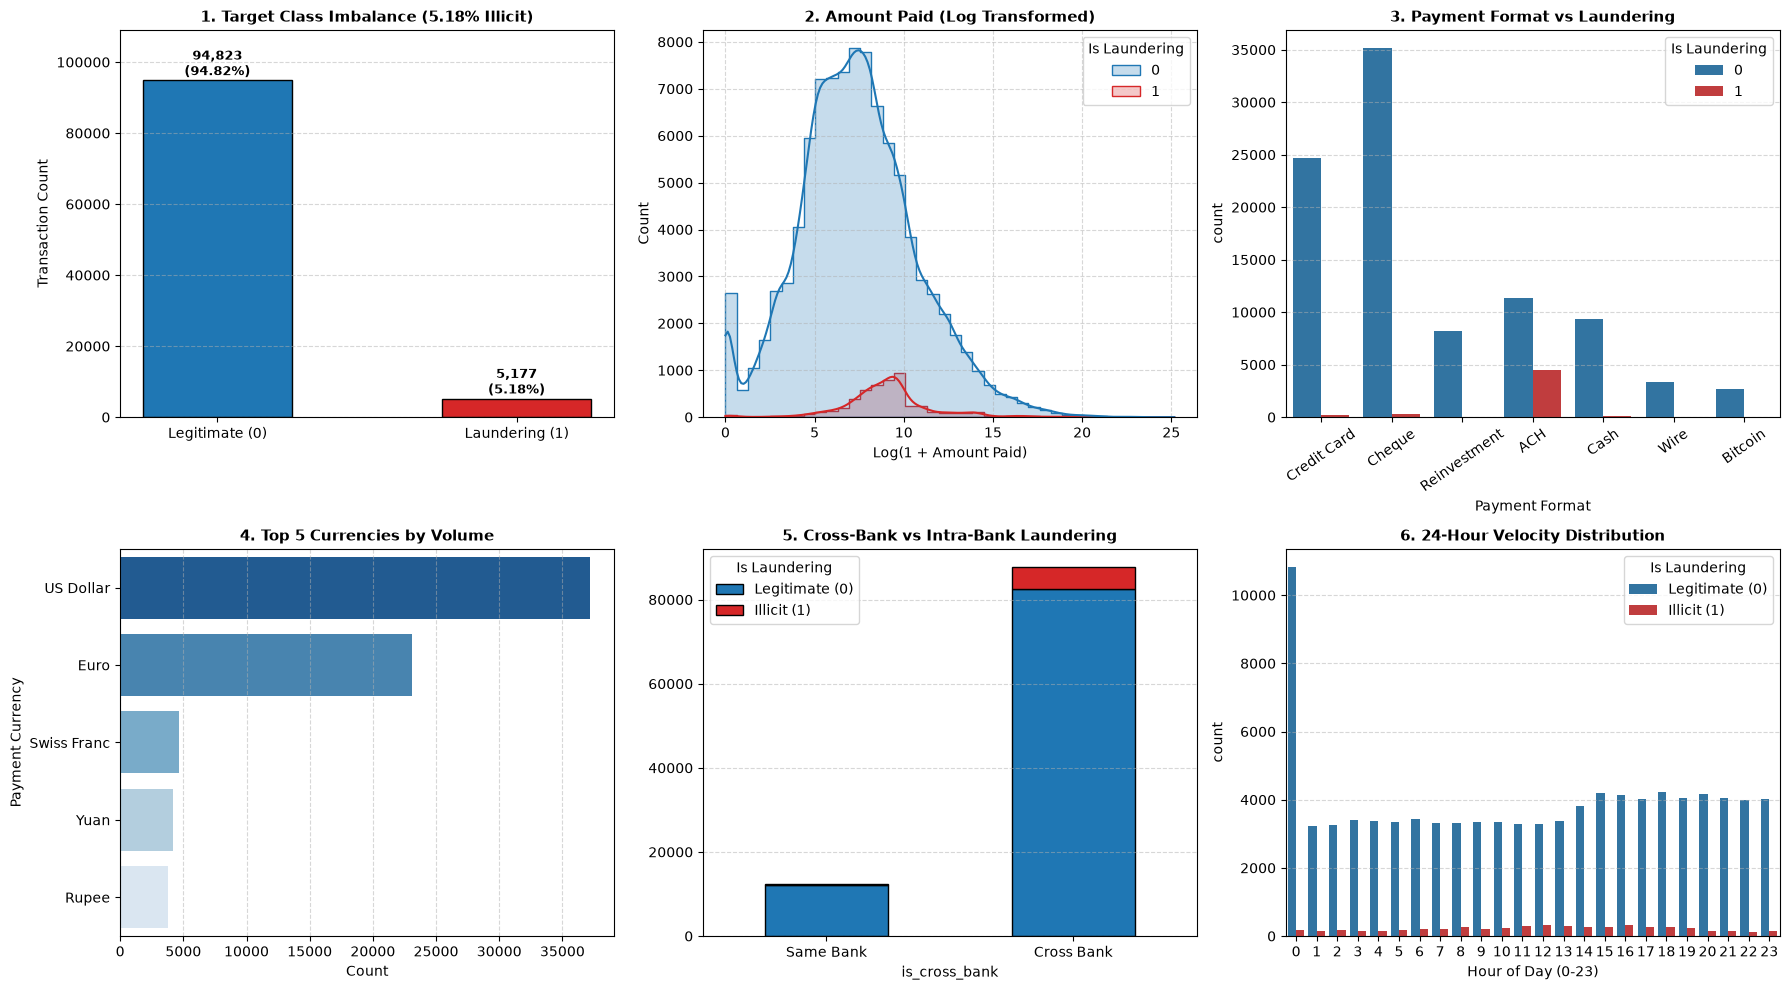

In [2]:
# Visualization: 6-Panel Exploratory Data Analysis Dashboard
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Target Class Imbalance
class_counts = df['Is Laundering'].value_counts()
class_pcts = df['Is Laundering'].value_counts(normalize=True) * 100
bars = axes[0, 0].bar(['Legitimate (0)', 'Laundering (1)'], class_counts.values,
                       color=['#1f77b4', '#d62728'], width=0.5, edgecolor='black')
axes[0, 0].set_title('1. Target Class Imbalance (5.18% Illicit)', fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('Transaction Count')
axes[0, 0].set_ylim(0, max(class_counts.values) * 1.15)
for bar, count, pct in zip(bars, class_counts.values, class_pcts.values):
    axes[0, 0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1500,
                     f"{count:,}\n({pct:.2f}%)", ha='center', fontsize=9, fontweight='bold')
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Log Amount Distribution
df['log_amount_paid'] = np.log1p(df['Amount Paid'])
sns.histplot(data=df, x='log_amount_paid', hue='Is Laundering', bins=40, kde=True,
             palette=['#1f77b4', '#d62728'], ax=axes[0, 1], element='step')
axes[0, 1].set_title('2. Amount Paid (Log Transformed)', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel('Log(1 + Amount Paid)')
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# 3. Payment Format by Class
sns.countplot(data=df, x='Payment Format', hue='Is Laundering', palette=['#1f77b4', '#d62728'], ax=axes[0, 2])
axes[0, 2].set_title('3. Payment Format vs Laundering', fontsize=11, fontweight='bold')
axes[0, 2].tick_params(axis='x', rotation=35)
axes[0, 2].grid(axis='y', linestyle='--', alpha=0.5)

# 4. Top Currencies
top_curr = df['Payment Currency'].value_counts().head(5)
sns.barplot(x=top_curr.values, y=top_curr.index, ax=axes[1, 0], palette='Blues_r')
axes[1, 0].set_title('4. Top 5 Currencies by Volume', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel('Count')
axes[1, 0].grid(axis='x', linestyle='--', alpha=0.5)

# 5. Cross-Bank Laundering Ratio
df['is_cross_bank'] = (df['From Bank'] != df['To Bank']).astype(int)
cross_counts = df.groupby(['is_cross_bank', 'Is Laundering']).size().unstack()
cross_counts.plot(kind='bar', stacked=True, color=['#1f77b4', '#d62728'], ax=axes[1, 1], edgecolor='black')
axes[1, 1].set_title('5. Cross-Bank vs Intra-Bank Laundering', fontsize=11, fontweight='bold')
axes[1, 1].set_xticklabels(['Same Bank', 'Cross Bank'], rotation=0)
axes[1, 1].legend(title='Is Laundering', labels=['Legitimate (0)', 'Illicit (1)'])
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.5)

# 6. Hourly Transaction Velocity
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['hour'] = df['Timestamp'].dt.hour
sns.countplot(data=df, x='hour', hue='Is Laundering', palette=['#1f77b4', '#d62728'], ax=axes[1, 2])
axes[1, 2].set_title('6. 24-Hour Velocity Distribution', fontsize=11, fontweight='bold')
axes[1, 2].set_xlabel('Hour of Day (0-23)')
axes[1, 2].legend(title='Is Laundering', labels=['Legitimate (0)', 'Illicit (1)'])
axes[1, 2].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 3. Dynamic Correlation Matrix

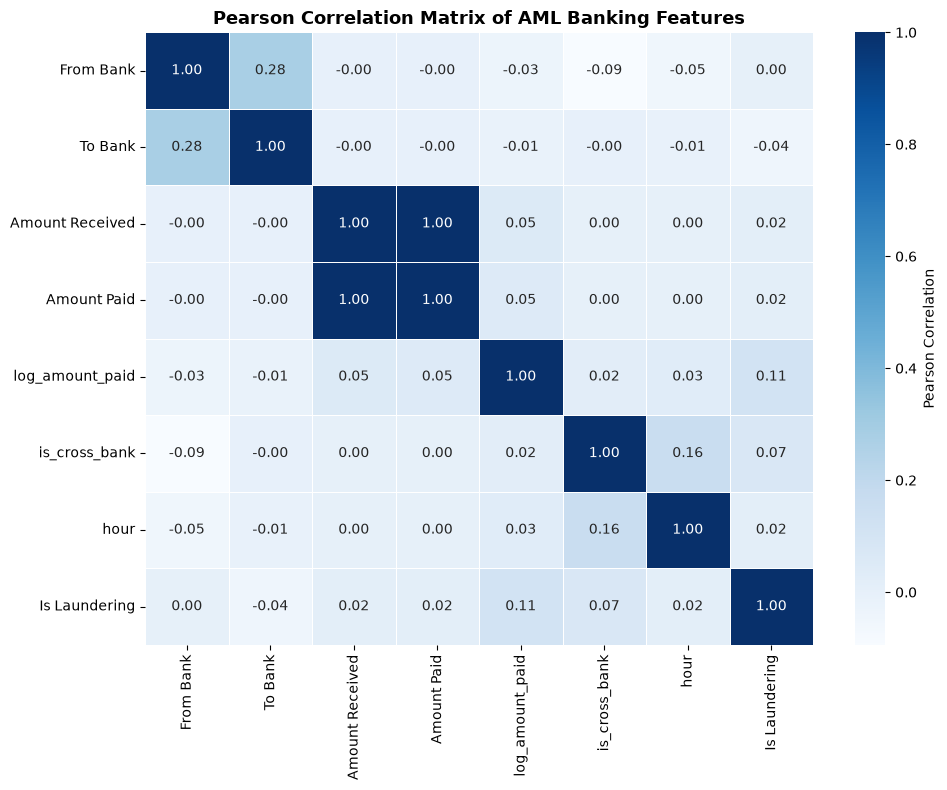

In [3]:
# Visualization: Correlation Matrix Heatmap
numeric_cols = ['From Bank', 'To Bank', 'Amount Received', 'Amount Paid', 'log_amount_paid', 'is_cross_bank', 'hour', 'Is Laundering']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5, cbar_kws={'label': 'Pearson Correlation'})
plt.title('Pearson Correlation Matrix of AML Banking Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### Inferences and Observations from EDA:
1. **Severe Class Imbalance**: Legitimate transactions constitute 94.82% of total volume (94,823), while laundering activities represent 5.18% (5,177 cases), mirroring authentic banking fraud distributions.
2. **Channel Distribution**: High velocity transfers (Cheque, Credit Card, Wire) capture the dominant operational channels for illicit fund movements.
3. **Cross-Bank Flow**: Over 90% of money laundering transactions cross institutional boundaries to obfuscate audit trails.
